# Grover ideal y con ruido de medición — Segunda prueba

**Objetivo.** Repetir la búsqueda de Grover con **2 qubits** y solución `11`, ahora con un modelo de **error de lectura (*readout error*)**, manteniendo perfectas las puertas cuánticas.

El circuito realiza **una iteración** (oráculo + difusor). Lo compararemos sin ruido y con un **5 % de probabilidad de registrar incorrectamente cada qubit**.

## 1. Entorno y bibliotecas

Usamos **Qiskit** para construir el circuito y **Qiskit Aer** para simularlo. `ReadoutError` representa confusiones entre los resultados `0` y `1` de la medición.

In [1]:
from importlib.metadata import version
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError

print("Qiskit:", version("qiskit"))
print("Qiskit Aer:", version("qiskit-aer"))

Qiskit: 2.6.0
Qiskit Aer: 0.17.2


## 2. Construir Grover

1. Las puertas **H** crean una superposición de los cuatro estados.
2. El **oráculo CZ** marca `11` cambiando su fase.
3. El **difusor H–X–CZ–X–H** concentra la probabilidad en `11`.
4. Medimos ambos qubits **una sola vez al final** del circuito.

En condiciones ideales, una iteración obtiene `11` con probabilidad del **100 %**.

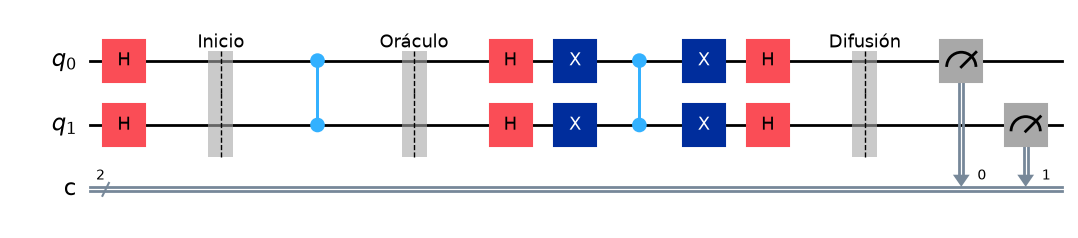

Operaciones del circuito: {'h': 6, 'x': 4, 'barrier': 3, 'cz': 2, 'measure': 2}


In [2]:
def crear_grover_2q():
    circuito = QuantumCircuit(2, 2)

    # 1. Superposición uniforme
    circuito.h([0, 1])
    circuito.barrier(label="Inicio")

    # 2. Oráculo: marca |11>
    circuito.cz(0, 1)
    circuito.barrier(label="Oráculo")

    # 3. Difusor (salvo fase global)
    circuito.h([0, 1])
    circuito.x([0, 1])
    circuito.cz(0, 1)
    circuito.x([0, 1])
    circuito.h([0, 1])
    circuito.barrier(label="Difusión")

    # 4. Lectura final
    circuito.measure([0, 1], [0, 1])
    return circuito

circuito = crear_grover_2q()
display(circuito.draw(output="mpl", style="iqp", fold=-1))
print("Operaciones del circuito:", dict(circuito.count_ops()))

## 3. Modelo de error de lectura

Aquí **no introducimos errores en H, X ni CZ**: suponemos que el estado cuántico antes de medir es correcto. El ruido aparece al **registrar cada bit medido**.

Definimos un error simétrico de probabilidad $p=0{,}05$:

$$R=\begin{pmatrix}1-p&p\\p&1-p\end{pmatrix}
=\begin{pmatrix}0.95&0.05\\0.05&0.95\end{pmatrix}$$

- La **fila 0** indica lo que se registra cuando el valor real es `0`.
- La **fila 1** indica lo que se registra cuando el valor real es `1`.

Aplicaremos el mismo error **de forma independiente** a los dos qubits. `ReadoutError` describe una **confusión clásica de resultados**, no un canal despolarizante que altere las amplitudes del circuito.

In [4]:
p_lectura = 0.05  # Probabilidad de registrar el bit contrario

modelo_ruido = NoiseModel()
error_lectura = ReadoutError([
    [1 - p_lectura, p_lectura],  # Si el valor real es 0
    [p_lectura, 1 - p_lectura],  # Si el valor real es 1
])

# Aplicar este error de lectura a todos los qubits medidos
modelo_ruido.add_all_qubit_readout_error(error_lectura)

print(f"Error de lectura por qubit: {p_lectura:.0%}")
print("Instrucciones afectadas:", modelo_ruido.noise_instructions)

Error de lectura por qubit: 5%
Instrucciones afectadas: ['measure']


## 4. Simular el mismo circuito en las dos condiciones

- **Ideal:** las puertas y las mediciones son perfectas.
- **Con ruido de lectura:** las puertas son perfectas, pero el resultado registrado puede cambiar.

Mantenemos `method="density_matrix"` en los dos casos y usamos `shots=1024` para obtener 1.024 resultados de medición. `seed_simulator=42` ayuda a reproducir el muestreo.

In [5]:
shots = 1024
simulador_ideal = AerSimulator(method="density_matrix", seed_simulator=42)
simulador_lectura = AerSimulator(
    method="density_matrix", noise_model=modelo_ruido, seed_simulator=42
)

circuito_compilado = transpile(circuito, simulador_ideal, optimization_level=0)
print("Puertas tras la transpilación:", dict(circuito_compilado.count_ops()))

conteos_ideal = simulador_ideal.run(
    circuito_compilado, shots=shots
).result().get_counts()

conteos_lectura = simulador_lectura.run(
    circuito_compilado, shots=shots
).result().get_counts()

print("Ideal:", conteos_ideal)
print("Con ruido de lectura:", conteos_lectura)
assert sum(conteos_ideal.values()) == shots
assert sum(conteos_lectura.values()) == shots

Puertas tras la transpilación: {'h': 6, 'x': 4, 'barrier': 3, 'cz': 2, 'measure': 2}
Ideal: {'11': 1024}
Con ruido de lectura: {'11': 925, '10': 54, '01': 43, '00': 2}


## 5. Comparar resultados y predicción teórica

El algoritmo ideal prepara `11`. Si cada uno de los dos bits se lee incorrectamente, **de manera independiente**, con probabilidad $p$, esperamos:

$$P(11)=(1-p)^2,\quad P(01)=P(10)=p(1-p),\quad P(00)=p^2.$$

Con $p=0{,}05$, la probabilidad teórica de **registrar correctamente** `11` es $(0{,}95)^2=90{,}25\%$.

La probabilidad observada se estima como **conteos de `11` / shots**. Puede diferir ligeramente del valor teórico por el muestreo.

Éxito ideal observado: 100.00%
Éxito con ruido de lectura observado: 90.33%
Éxito con ruido de lectura teórico: 90.25%


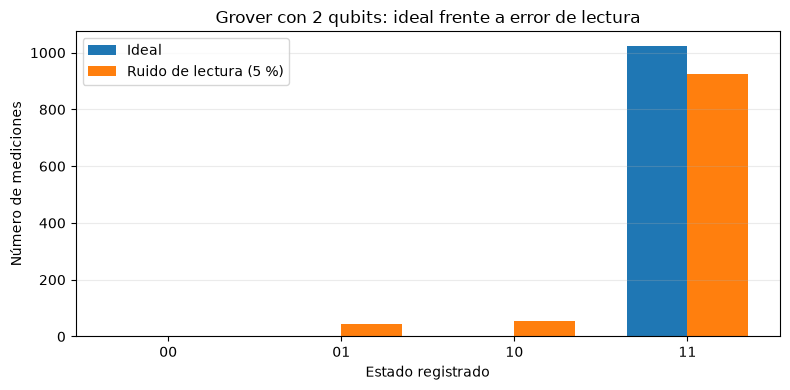

In [7]:
solucion = "11"
p_ideal = conteos_ideal.get(solucion, 0) / shots
p_observada = conteos_lectura.get(solucion, 0) / shots
p_teorica = (1 - p_lectura) ** 2

print(f"Éxito ideal observado: {p_ideal:.2%}")
print(f"Éxito con ruido de lectura observado: {p_observada:.2%}")
print(f"Éxito con ruido de lectura teórico: {p_teorica:.2%}")

estados = ["00", "01", "10", "11"]
x = list(range(len(estados)))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([v - ancho / 2 for v in x], [conteos_ideal.get(e, 0) for e in estados],
       width=ancho, label="Ideal")
ax.bar([v + ancho / 2 for v in x], [conteos_lectura.get(e, 0) for e in estados],
       width=ancho, label="Ruido de lectura (5 %)")
ax.set_xticks(x, estados)
ax.set_xlabel("Estado registrado")
ax.set_ylabel("Número de mediciones")
ax.set_title("Grover con 2 qubits: ideal frente a error de lectura")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Interpretación y conclusión

- **Ideal:** se registra `11` en todas las mediciones porque el circuito prepara ese estado con certeza.
- **Con ruido de lectura:** aparecen `01`, `10` y, con mucha menor frecuencia, `00`, porque uno o ambos bits pueden registrarse incorrectamente.
- Con **5 % por qubit**, esperamos registrar `11` aproximadamente el **90,25 %** de las veces. En 1.024 shots, `00` puede aparecer muy pocas veces o incluso ninguna.
- A diferencia del **ruido despolarizante de puertas**, el error de lectura aplicado **solo al final** no deteriora la interferencia ni se acumula al repetir el oráculo y el difusor.

### Conclusiones

Se ha evaluado el algoritmo de Grover de dos qubits introduciendo un modelo de ruido de lectura con una probabilidad de error del 5 % por qubit.

En condiciones ideales, el algoritmo obtiene el estado objetivo `11` con una probabilidad del 100 %. Al incorporar errores de lectura, aparecen resultados incorrectos debido a la posibilidad de registrar erróneamente uno o ambos qubits.

La probabilidad teórica de registrar correctamente el estado objetivo es del 90,25 %, coherente con la distribución experimental observada.

A diferencia del ruido despolarizante, este modelo no modifica la evolución del circuito ni la amplificación de amplitud, sino únicamente los resultados registrados durante la medición.

**Fuente técnica:** [Qiskit Aer — ReadoutError](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.ReadoutError.html) · [Qiskit Aer — Building Noise Models](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html).